# Phase 3 - Notebook 4: Evaluacion de Calidad de Embeddings para Clustering

Este notebook evalua la calidad del embedding generado con `padding + attention` para tareas de clustering.

Incluye:
1. Preparacion de datos y estandarizacion
2. Benchmark de algoritmos (KMeans y GMM)
3. Seleccion de mejor configuracion
4. Evaluacion temporal (train/val/test)
5. Estabilidad por semilla
6. Alineacion con labels proxy
7. Validacion economica por cluster (retorno futuro)
8. Export de reportes


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)

try:
    from scipy.stats import kruskal
    HAS_SCIPY = True
except Exception:
    HAS_SCIPY = False

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 300)


In [2]:
# =========================
# Config
# =========================
EMB_PATH = Path('./phases/phase03_segment_analysis/output_attention_v2/USDJPY_segments_attention_embeddings.parquet')
CATALOG_PATH = Path('./phases/phase03_segment_analysis/output_extraccion/USDJPY_segments_extracted_catalog.parquet')
PRICE_PATH = Path('./data/Dataset_H1_v1/parquet_h1/USDJPY.parquet')

OUTPUT_DIR = Path('./phases/phase03_segment_analysis/output_eval_clustering')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LEADERBOARD_CSV = OUTPUT_DIR / 'clustering_leaderboard.csv'
SPLIT_METRICS_CSV = OUTPUT_DIR / 'clustering_split_metrics.csv'
STABILITY_CSV = OUTPUT_DIR / 'clustering_stability.csv'
PROXY_METRICS_CSV = OUTPUT_DIR / 'clustering_proxy_metrics.csv'
ECON_SUMMARY_CSV = OUTPUT_DIR / 'clustering_economic_summary.csv'
ASSIGNMENTS_PARQUET = OUTPUT_DIR / 'segment_cluster_assignments.parquet'
ASSIGNMENTS_CSV = OUTPUT_DIR / 'segment_cluster_assignments.csv'

K_GRID = list(range(2, 13))
SEEDS_STABILITY = [3, 7, 11, 19, 23, 29, 31, 41]
HORIZON_HOURS = 24

print('EMB_PATH =', EMB_PATH)
print('OUTPUT_DIR =', OUTPUT_DIR)


EMB_PATH = ./phases/phase03_segment_analysis/output_attention_v2/USDJPY_segments_attention_embeddings.parquet
OUTPUT_DIR = ./phases/phase03_segment_analysis/output_eval_clustering


In [3]:
# =========================
# Carga
# =========================
if not EMB_PATH.exists():
    raise FileNotFoundError(f'No existe EMB_PATH: {EMB_PATH}')

EMB = pd.read_parquet(EMB_PATH).copy()
if not CATALOG_PATH.exists():
    raise FileNotFoundError(f'No existe CATALOG_PATH: {CATALOG_PATH}')
CAT = pd.read_parquet(CATALOG_PATH).copy()

EMB['start_ts'] = pd.to_datetime(EMB['start_ts'], errors='coerce')
CAT['start_ts'] = pd.to_datetime(CAT['start_ts'], errors='coerce')

# merge metadata adicional
add_cols = [c for c in ['global_segment_id', 'segment_label_unified', 'move_pips_extracted', 'range_pips_extracted', 'n_bars_extracted'] if c in CAT.columns]
META = CAT[add_cols].drop_duplicates('global_segment_id')
DF = EMB.merge(META, on='global_segment_id', how='left')

emb_cols = [c for c in DF.columns if c.startswith('emb_')]
if len(emb_cols) == 0:
    raise RuntimeError('No se encontraron columnas emb_ en embeddings.')

DF = DF.dropna(subset=emb_cols).copy()
DF = DF.sort_values('start_ts').reset_index(drop=True)

print('Rows =', len(DF), '| Emb dim =', len(emb_cols))
print('Split counts:')
print(DF['split'].value_counts(dropna=False).to_string())
print('Origin counts:')
print(DF['segment_origin'].value_counts(dropna=False).to_string())
display(DF.head(5))


Rows = 991 | Emb dim = 48
Split counts:
split
train    695
test     149
val      147
Origin counts:
segment_origin
automatico    430
manual        356
ia            205


,global_segment_id,emb_000,emb_001,emb_002,emb_003,emb_004,emb_005,emb_006,emb_007,emb_008,emb_009,emb_010,emb_011,emb_012,emb_013,emb_014,emb_015,emb_016,emb_017,emb_018,emb_019,emb_020,emb_021,emb_022,emb_023,emb_024,emb_025,emb_026,emb_027,emb_028,emb_029,emb_030,emb_031,emb_032,emb_033,emb_034,emb_035,emb_036,emb_037,emb_038,emb_039,emb_040,emb_041,emb_042,emb_043,emb_044,emb_045,emb_046,emb_047,segment_origin,source_name,split,start_ts,length,segment_label_unified,move_pips_extracted,range_pips_extracted,n_bars_extracted
0,beyond_sota_000090,-1.094762,1.793748,-0.937789,-0.207897,-0.557138,1.858881,-1.040469,0.428216,-1.493298,-0.817512,0.432608,-0.177158,1.880613,0.623608,0.542556,-0.113326,0.114328,-0.083018,-1.191410,-2.229041,0.670185,-0.668418,-0.690475,-0.248814,0.740732,-1.114732,0.684118,-1.441275,0.172768,-2.202819,-1.117872,-1.082269,2.219327,1.520297,-1.006404,-0.911890,2.918053,0.932091,2.125161,-1.111900,3.153691,1.454454,0.392684,-0.343070,-1.405919,1.205274,-1.653366,-3.206351,automatico,beyond_sota,train,2015-01-01 13:00:00,19,NaN,95.199585,107.599640,19
1,beyond_sota_000180,-0.083491,2.657002,0.374275,-0.633048,-0.796021,0.625821,1.257504,-0.398449,-2.398483,1.860239,1.565237,0.336744,1.157854,-0.521674,-1.268219,1.416313,-2.530344,-1.394327,-0.580070,0.578444,-0.420766,-0.341667,-0.201182,1.096141,-0.327797,1.585972,0.458981,-1.981672,-0.127635,-1.512026,-1.940956,-0.041652,2.713020,1.762698,-0.089727,-1.103718,1.089113,1.487951,3.038683,0.415468,0.173933,-1.110118,0.079629,-1.488315,-1.689789,1.236793,-0.963856,0.114530,automatico,beyond_sota,train,2015-01-02 10:00:00,8,NaN,33.699799,81.400299,8
2,beyond_sota_000235,-0.347829,0.393427,0.870559,1.910046,1.811869,-1.969483,0.389457,-1.373945,1.247159,-0.167123,-0.458844,-1.003984,-3.179366,0.117550,-1.724616,-0.499463,-0.378159,-0.895648,1.131314,1.835003,-1.265407,1.594566,-0.326522,1.459498,-1.250956,-0.382045,-2.722780,1.349345,-0.373232,1.398845,0.374736,-0.340176,-1.841002,1.311604,-0.045765,1.526644,-2.440532,-0.067387,0.064317,3.473794,-1.842349,-1.925138,-0.843048,-1.477018,-0.339265,0.398200,0.632286,1.947040,automatico,beyond_sota,train,2015-01-04 21:00:00,25,NaN,-99.700165,148.699951,25
3,beyond_sota_000077,2.212510,-3.266852,4.380256,3.902111,1.872099,-2.100031,0.194653,-0.302896,3.547516,-1.446604,0.143662,0.947632,0.694206,1.135916,0.143845,-0.238334,3.854186,-0.027979,-0.188921,-1.218000,2.610133,4.114197,-1.089898,-1.576017,-1.064461,0.872834,-2.202065,2.136582,4.183317,1.682555,1.024965,4.170973,-2.381741,-3.198413,-2.241801,-1.564388,-0.339171,-2.214423,-1.597255,1.076888,0.414266,0.846368,1.087974,0.398295,0.782729,-0.193943,2.282531,-0.330757,automatico,beyond_sota,train,2015-01-05 20:00:00,6,NaN,-65.100098,79.599762,6
4,beyond_sota_000009,2.330078,-3.076401,4.243559,3.763252,1.706246,-2.138884,0.229209,-0.098411,3.625012,-1.333742,-0.014116,1.134645,0.557717,1.010681,0.139264,-0.396062,3.605742,-0.253524,-0.034448,-0.907132,2.443181,3.993137,-1.135289,-1.559360,-0.896063,0.947124,-2.138392,2.039490,3.818485,1.675625,0.735204,4.040454,-2.181101,-3.072297,-2.145309,-1.476433,-0.216567,-2.252977,-1.532653,1.136247,0.357943,0.661976,1.313644,0.406267,0.755467,-0.280399,2.268949,-0.179291,automatico,beyond_sota,train,2015-01-06 06:00:00,6,NaN,-109.600067,119.100189,6


In [4]:
# =========================
# Escalado train-only
# =========================
train_mask = DF['split'] == 'train'
if train_mask.sum() < 50:
    raise RuntimeError('Muy pocos datos de train para evaluar clustering.')

X_train_raw = DF.loc[train_mask, emb_cols].to_numpy(dtype=float)
X_all_raw = DF[emb_cols].to_numpy(dtype=float)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_all = scaler.transform(X_all_raw)

print('X_train shape =', X_train.shape)
print('X_all shape =', X_all.shape)


X_train shape = (695, 48)
X_all shape = (991, 48)


In [5]:
# =========================
# Benchmark de clustering en train
# =========================
def cluster_metrics(x: np.ndarray, labels: np.ndarray) -> dict:
    n_clusters = len(np.unique(labels))
    out = {'n_clusters': int(n_clusters), 'silhouette': np.nan, 'dbi': np.nan, 'ch': np.nan}
    if n_clusters <= 1:
        return out
    out['silhouette'] = float(silhouette_score(x, labels))
    out['dbi'] = float(davies_bouldin_score(x, labels))
    out['ch'] = float(calinski_harabasz_score(x, labels))
    return out


rows = []

for k in K_GRID:
    # KMeans
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    lbl_km = km.fit_predict(X_train)
    met = cluster_metrics(X_train, lbl_km)
    rows.append({
        'algo': 'kmeans',
        'k': k,
        **met,
        'bic': np.nan,
        'aic': np.nan,
    })

    # GMM
    gm = GaussianMixture(n_components=k, covariance_type='full', random_state=42, reg_covar=1e-5)
    gm.fit(X_train)
    lbl_gm = gm.predict(X_train)
    metg = cluster_metrics(X_train, lbl_gm)
    rows.append({
        'algo': 'gmm',
        'k': k,
        **metg,
        'bic': float(gm.bic(X_train)),
        'aic': float(gm.aic(X_train)),
    })

LEAD = pd.DataFrame(rows)

# ranking compuesto: silhouette (max), ch (max), dbi (min), bic/aic (min para gmm)
LEAD['rank_sil'] = LEAD['silhouette'].rank(ascending=False, method='min')
LEAD['rank_ch'] = LEAD['ch'].rank(ascending=False, method='min')
LEAD['rank_dbi'] = LEAD['dbi'].rank(ascending=True, method='min')
LEAD['rank_bic'] = LEAD['bic'].rank(ascending=True, method='min', na_option='bottom')
LEAD['rank_aic'] = LEAD['aic'].rank(ascending=True, method='min', na_option='bottom')

LEAD['rank_total'] = LEAD['rank_sil'] + LEAD['rank_ch'] + LEAD['rank_dbi'] + 0.25 * (LEAD['rank_bic'] + LEAD['rank_aic'])
LEAD = LEAD.sort_values('rank_total').reset_index(drop=True)

LEAD.to_csv(LEADERBOARD_CSV, index=False)

print('Top 10 leaderboard:')
display(LEAD.head(10))
print('Guardado:', LEADERBOARD_CSV)


Top 10 leaderboard:


,algo,k,n_clusters,silhouette,dbi,ch,bic,aic,rank_sil,rank_ch,rank_dbi,rank_bic,rank_aic,rank_total
0,kmeans,10,10,0.342224,0.942735,370.258472,NaN,NaN,5.0,10.0,1.0,12.0,12.0,22.00
1,kmeans,12,12,0.339419,0.952923,373.843049,NaN,NaN,7.0,8.0,2.0,12.0,12.0,23.00
2,gmm,3,3,0.360103,1.081455,395.128503,-116619.891499,-133314.223620,4.0,5.0,14.0,8.0,10.0,27.50
3,kmeans,2,2,0.381569,1.160935,463.954982,NaN,NaN,1.0,1.0,20.0,12.0,12.0,28.00
4,kmeans,3,3,0.360223,1.082507,395.230939,NaN,NaN,3.0,4.0,15.0,12.0,12.0,28.00
5,kmeans,9,9,0.334187,0.958210,371.049595,NaN,NaN,11.0,9.0,4.0,12.0,12.0,30.00
6,gmm,2,2,0.381567,1.161051,463.947390,-110614.019243,-121742.059353,2.0,2.0,21.0,10.0,11.0,30.25
7,kmeans,11,11,0.336297,0.953275,370.013650,NaN,NaN,10.0,12.0,3.0,12.0,12.0,31.00
8,kmeans,8,8,0.341722,0.989652,367.763999,NaN,NaN,6.0,14.0,6.0,12.0,12.0,32.00
9,kmeans,4,4,0.338354,1.138368,406.908017,NaN,NaN,9.0,3.0,18.0,12.0,12.0,36.00


Guardado: ./phases/phase03_segment_analysis/output_eval_clustering/clustering_leaderboard.csv


In [6]:
# =========================
# Seleccion de mejor modelo y asignacion all-split
# =========================
best = LEAD.iloc[0]
best_algo = str(best['algo'])
best_k = int(best['k'])

print('Best algo:', best_algo, '| k =', best_k)

if best_algo == 'kmeans':
    model = KMeans(n_clusters=best_k, random_state=42, n_init=30)
    model.fit(X_train)
    cluster_all = model.predict(X_all)
elif best_algo == 'gmm':
    model = GaussianMixture(n_components=best_k, covariance_type='full', random_state=42, reg_covar=1e-5)
    model.fit(X_train)
    cluster_all = model.predict(X_all)
else:
    raise RuntimeError('Algoritmo no soportado para asignacion all-split.')

DF['cluster_id'] = cluster_all.astype(int)

print('Cluster sizes (all):')
print(DF['cluster_id'].value_counts().sort_index().to_string())


Best algo: kmeans | k = 10
Cluster sizes (all):
cluster_id
0     64
1     78
2     96
3     70
4    100
5    143
6    133
7    134
8    103
9     70


In [7]:
# =========================
# Evaluacion por split temporal
# =========================
split_rows = []
for sp in ['train', 'val', 'test']:
    d = DF[DF['split'] == sp]
    if len(d) < 10:
        continue

    x = X_all[d.index]
    y = d['cluster_id'].to_numpy()
    m = cluster_metrics(x, y)
    split_rows.append({'split': sp, 'n': len(d), **m})

SPLIT_MET = pd.DataFrame(split_rows)
SPLIT_MET.to_csv(SPLIT_METRICS_CSV, index=False)

display(SPLIT_MET)
print('Guardado:', SPLIT_METRICS_CSV)


,split,n,n_clusters,silhouette,dbi,ch
0,train,695,10,0.343347,0.939955,370.813634
1,val,147,10,0.216034,1.121345,50.811886
2,test,149,7,0.195035,1.024424,127.260862


Guardado: ./phases/phase03_segment_analysis/output_eval_clustering/clustering_split_metrics.csv


In [8]:
# =========================
# Estabilidad por semilla (train)
# =========================
train_idx = np.where(train_mask.to_numpy())[0]
Xtr = X_all[train_idx]

labels_by_seed = {}
for sd in SEEDS_STABILITY:
    if best_algo == 'kmeans':
        m = KMeans(n_clusters=best_k, random_state=sd, n_init=20)
        y = m.fit_predict(Xtr)
    else:
        m = GaussianMixture(n_components=best_k, covariance_type='full', random_state=sd, reg_covar=1e-5)
        m.fit(Xtr)
        y = m.predict(Xtr)
    labels_by_seed[sd] = y

pairs = []
seeds = list(labels_by_seed.keys())
for i in range(len(seeds)):
    for j in range(i + 1, len(seeds)):
        s1, s2 = seeds[i], seeds[j]
        ari = adjusted_rand_score(labels_by_seed[s1], labels_by_seed[s2])
        nmi = normalized_mutual_info_score(labels_by_seed[s1], labels_by_seed[s2])
        pairs.append({'seed_a': s1, 'seed_b': s2, 'ari': float(ari), 'nmi': float(nmi)})

STAB = pd.DataFrame(pairs)
STAB.to_csv(STABILITY_CSV, index=False)

print('Stability summary:')
print(STAB[['ari','nmi']].describe().to_string())
print('Guardado:', STABILITY_CSV)


Stability summary:
             ari        nmi
count  28.000000  28.000000
mean    0.935911   0.947103
std     0.036289   0.026827
min     0.871790   0.903306
25%     0.907825   0.925563
50%     0.936628   0.951057
75%     0.965563   0.966853
max     1.000000   1.000000
Guardado: ./phases/phase03_segment_analysis/output_eval_clustering/clustering_stability.csv


In [9]:
# =========================
# Alineacion con labels proxy
# =========================
proxy_candidates = ['segment_label_unified', 'segment_origin', 'source_name']
proxy_rows = []

for col in proxy_candidates:
    if col not in DF.columns:
        continue

    d = DF[[col, 'cluster_id', 'split']].dropna().copy()
    if d.empty:
        continue

    # all
    y_true = LabelEncoder().fit_transform(d[col].astype(str))
    y_pred = d['cluster_id'].to_numpy()
    proxy_rows.append({
        'proxy_col': col,
        'scope': 'all',
        'n': len(d),
        'nmi': float(normalized_mutual_info_score(y_true, y_pred)),
        'ari': float(adjusted_rand_score(y_true, y_pred)),
    })

    # train
    dt = d[d['split'] == 'train']
    if len(dt) > 0:
        yt = LabelEncoder().fit_transform(dt[col].astype(str))
        yp = dt['cluster_id'].to_numpy()
        proxy_rows.append({
            'proxy_col': col,
            'scope': 'train',
            'n': len(dt),
            'nmi': float(normalized_mutual_info_score(yt, yp)),
            'ari': float(adjusted_rand_score(yt, yp)),
        })

PROXY = pd.DataFrame(proxy_rows)
PROXY.to_csv(PROXY_METRICS_CSV, index=False)

display(PROXY)
print('Guardado:', PROXY_METRICS_CSV)


,proxy_col,scope,n,nmi,ari
0,segment_label_unified,all,205,0.276991,0.225032
1,segment_origin,all,991,0.135611,0.052465
2,segment_origin,train,695,0.077155,0.038009
3,source_name,all,991,0.135611,0.052465
4,source_name,train,695,0.077155,0.038009


Guardado: ./phases/phase03_segment_analysis/output_eval_clustering/clustering_proxy_metrics.csv


In [10]:
# =========================
# Validacion economica: retorno futuro por cluster (test)
# =========================
if not PRICE_PATH.exists():
    raise FileNotFoundError(f'No existe PRICE_PATH: {PRICE_PATH}')

px = pd.read_parquet(PRICE_PATH, columns=['timestamp', 'close']).copy()
px['timestamp'] = pd.to_datetime(px['timestamp'], errors='coerce')
px['close'] = pd.to_numeric(px['close'], errors='coerce')
px = px.dropna(subset=['timestamp', 'close']).sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)

idx = px['timestamp'].to_numpy(dtype='datetime64[ns]')
close = px['close'].to_numpy(dtype=float)

start = DF['start_ts'].to_numpy(dtype='datetime64[ns]')
pos = np.searchsorted(idx, start, side='left')

valid = (pos >= 0) & (pos < len(idx))
exact = valid & (idx[np.clip(pos, 0, len(idx)-1)] == start)
future_pos = pos + int(HORIZON_HOURS)
valid_future = exact & (future_pos < len(idx))

fwd = np.full(len(DF), np.nan, dtype=float)
vol = np.full(len(DF), np.nan, dtype=float)

use_idx = np.where(valid_future)[0]
for i in use_idx:
    p0 = pos[i]
    p1 = future_pos[i]
    fwd[i] = (close[p1] - close[p0]) / 0.01  # USDJPY pips
    seg = close[p0:p1+1]
    if len(seg) > 1:
        lr = np.diff(np.log(np.clip(seg, 1e-12, None)))
        vol[i] = float(np.std(lr) * np.sqrt(len(lr)))

DF['fwd_ret_pips_h24'] = fwd
DF['fwd_vol_h24'] = vol

TEST = DF[(DF['split'] == 'test') & DF['fwd_ret_pips_h24'].notna()].copy()

ECO = (
    TEST.groupby('cluster_id', dropna=False)
    .agg(
        n=('cluster_id', 'count'),
        mean_ret=('fwd_ret_pips_h24', 'mean'),
        median_ret=('fwd_ret_pips_h24', 'median'),
        std_ret=('fwd_ret_pips_h24', 'std'),
        mean_vol=('fwd_vol_h24', 'mean'),
    )
    .reset_index()
    .sort_values('cluster_id')
)
ECO['ret_t_like'] = ECO['mean_ret'] / (ECO['std_ret'].replace(0, np.nan))

# test estadistico simple de diferencia entre clusters
p_kw = np.nan
if HAS_SCIPY and len(ECO) >= 2:
    groups = [g['fwd_ret_pips_h24'].to_numpy() for _, g in TEST.groupby('cluster_id') if len(g) >= 3]
    if len(groups) >= 2:
        try:
            _, p_kw = kruskal(*groups)
        except Exception:
            p_kw = np.nan

ECO.to_csv(ECON_SUMMARY_CSV, index=False)

print('Test rows con fwd_ret:', len(TEST))
print('Kruskal p-value (retorno entre clusters) =', p_kw)
display(ECO)
print('Guardado:', ECON_SUMMARY_CSV)


Test rows con fwd_ret: 149
Kruskal p-value (retorno entre clusters) = 1.698492362201729e-11


,cluster_id,n,mean_ret,median_ret,std_ret,mean_vol,ret_t_like
0,0,1,15.799713,15.799713,NaN,0.003502,NaN
1,2,21,4.361943,-4.200745,31.091017,0.003148,0.140296
2,3,5,7.180023,14.600372,22.146802,0.003692,0.324201
3,4,3,-13.533274,-4.599762,20.236909,0.002281,-0.668742
4,5,41,26.580550,31.300354,34.713296,0.003628,0.765717
5,6,27,17.711046,10.600281,39.257413,0.003462,0.451152
6,7,51,-39.423565,-31.700134,43.337639,0.004383,-0.909684


Guardado: ./phases/phase03_segment_analysis/output_eval_clustering/clustering_economic_summary.csv


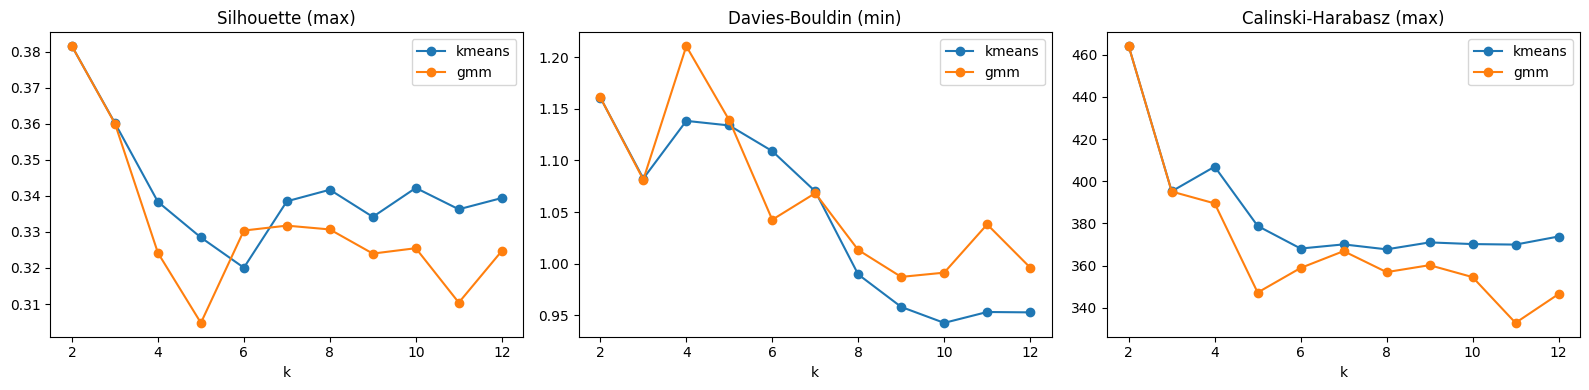

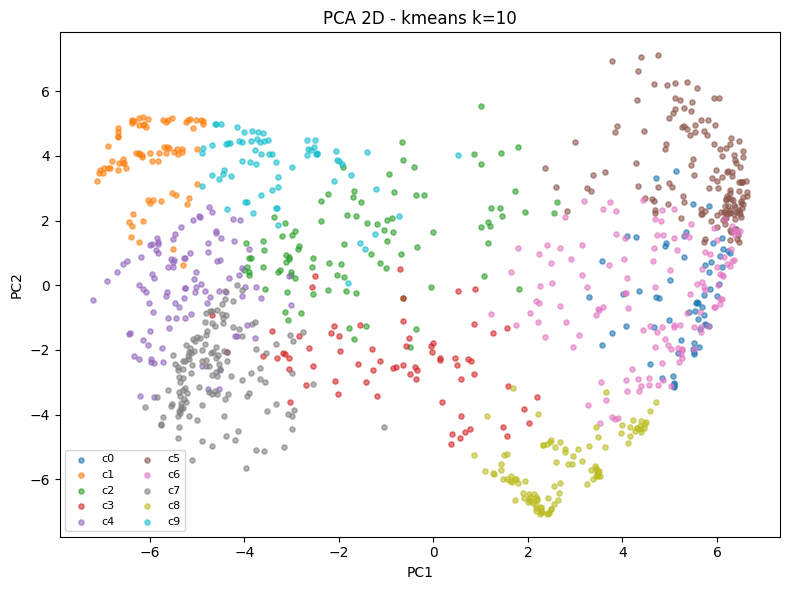

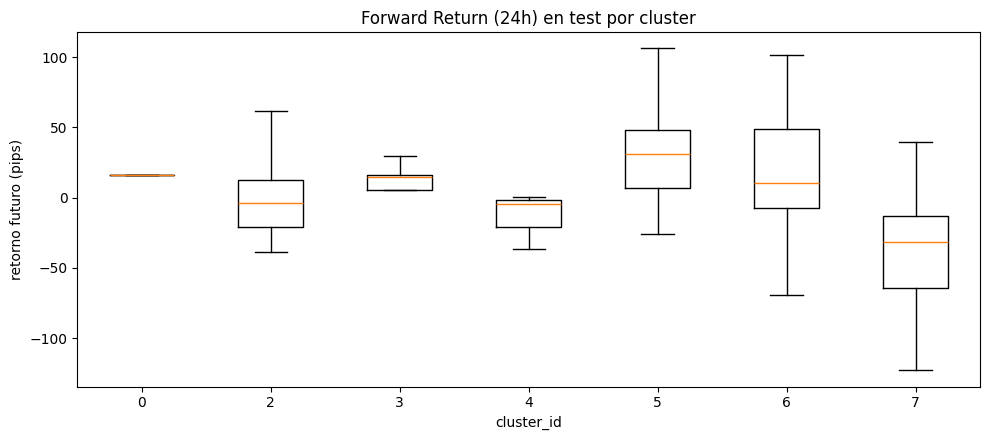

In [11]:
# =========================
# Visualizaciones
# =========================
# 1) Curva de calidad por k
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for algo in ['kmeans', 'gmm']:
    d = LEAD[LEAD['algo'] == algo].sort_values('k')
    axes[0].plot(d['k'], d['silhouette'], marker='o', label=algo)
    axes[1].plot(d['k'], d['dbi'], marker='o', label=algo)
    axes[2].plot(d['k'], d['ch'], marker='o', label=algo)
axes[0].set_title('Silhouette (max)')
axes[1].set_title('Davies-Bouldin (min)')
axes[2].set_title('Calinski-Harabasz (max)')
for ax in axes:
    ax.set_xlabel('k')
    ax.legend()
plt.tight_layout()
plt.show()

# 2) PCA 2D por cluster
pca = PCA(n_components=2, random_state=42)
xy = pca.fit_transform(X_all)
P = pd.DataFrame({'pc1': xy[:,0], 'pc2': xy[:,1], 'cluster': DF['cluster_id'], 'split': DF['split']})

fig, ax = plt.subplots(figsize=(8, 6))
for cid, g in P.groupby('cluster'):
    ax.scatter(g['pc1'], g['pc2'], s=14, alpha=0.6, label=f'c{cid}')
ax.set_title(f'PCA 2D - {best_algo} k={best_k}')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

# 3) Boxplot retorno futuro test por cluster
if len(TEST) > 0:
    ids = sorted(TEST['cluster_id'].unique().tolist())
    data = [TEST.loc[TEST['cluster_id'] == cid, 'fwd_ret_pips_h24'].to_numpy() for cid in ids]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.boxplot(data, tick_labels=[str(c) for c in ids], showfliers=False)
    ax.set_title('Forward Return (24h) en test por cluster')
    ax.set_xlabel('cluster_id')
    ax.set_ylabel('retorno futuro (pips)')
    plt.tight_layout()
    plt.show()


In [12]:
# =========================
# Export final de asignaciones
# =========================
out_cols = [
    'global_segment_id', 'start_ts', 'split', 'segment_origin', 'source_name',
    'segment_label_unified', 'length', 'cluster_id', 'fwd_ret_pips_h24', 'fwd_vol_h24'
]
out_cols = [c for c in out_cols if c in DF.columns]
ASSIGN = DF[out_cols + emb_cols].copy()

ASSIGN.to_parquet(ASSIGNMENTS_PARQUET, index=False)
ASSIGN.to_csv(ASSIGNMENTS_CSV, index=False)

print('Guardado final:')
print(' -', ASSIGNMENTS_PARQUET)
print(' -', ASSIGNMENTS_CSV)
print(' -', LEADERBOARD_CSV)
print(' -', SPLIT_METRICS_CSV)
print(' -', STABILITY_CSV)
print(' -', PROXY_METRICS_CSV)
print(' -', ECON_SUMMARY_CSV)


Guardado final:
 - ./phases/phase03_segment_analysis/output_eval_clustering/segment_cluster_assignments.parquet
 - ./phases/phase03_segment_analysis/output_eval_clustering/segment_cluster_assignments.csv
 - ./phases/phase03_segment_analysis/output_eval_clustering/clustering_leaderboard.csv
 - ./phases/phase03_segment_analysis/output_eval_clustering/clustering_split_metrics.csv
 - ./phases/phase03_segment_analysis/output_eval_clustering/clustering_stability.csv
 - ./phases/phase03_segment_analysis/output_eval_clustering/clustering_proxy_metrics.csv
 - ./phases/phase03_segment_analysis/output_eval_clustering/clustering_economic_summary.csv


## Interpretacion rapida

- Si `silhouette` es bajo y `dbi` alto, el embedding no separa bien clusters.
- Si ARI/NMI de estabilidad son bajos entre semillas, el clustering no es robusto.
- Si hay diferencias de `fwd_ret_pips_h24` entre clusters en test (y p-value bajo), el embedding tiene valor economico potencial.
